# Multi-objective optimization: L-tyrosine in yeast

This example searches for reaction bound modifications that increase L-tyrosine production in yeast, with the iMM904SL_v6 model.

- The medium limits glucose uptake to 10 mmol/gDW/h and oxygen uptake to 12.25 mmol/gDW/h.
- Two objective functions guide the search:
    - the weighted yield (WYIELD): 0.3 × maximum + 0.7 × minimum tyrosine secretion (from FVA), with growth at least 99% of the candidate's FBA growth;
    - the biomass-product coupled yield (BPCY): growth × tyrosine secretion / glucose uptake, from lMOMA predictions.
- Solutions have at most 10 modifications.

The first step loads the model and defines the medium:

In [1]:
from reframed.io.sbml import load_cbmodel
from mewpy.problems import ROUProblem
from mewpy.optimization.evaluation import BPCY, WYIELD
from mewpy.optimization import EA

%matplotlib inline

model = load_cbmodel('models/yeast/iMM904SL_v6.xml', flavor='cobra')

# Some constants to ease the configuration
BIOMASS_ID = 'R_biomass_SC5_notrace'
PRODUCT_ID = 'R_EX_tyr_L_e_'
O2 = 'R_EX_o2_e_'
GLC = 'R_EX_glc_e_'

# Medium definition
envcond = {GLC: (-10.0, 999999.0), O2: (-12.25, 100000.0)}

# Set the model objective
model.set_objective({BIOMASS_ID: 1})

By default, a `ROUProblem` may modify any reaction, including exchange reactions such as the glucose or tyrosine exchanges. The examples include a list of reactions of this model not to modify, which excludes them:

In [2]:
with open('models/yeast/nontargets#ROU#iMM904SL_v6#[lim-aerobic#glucose].txt') as f:
    non_target = [line.strip() for line in f if line.strip()]

print(len(non_target), 'non-targets, of which', sum(r.startswith('R_EX_') for r in non_target), 'exchange reactions')
print([r for r in (GLC, O2, PRODUCT_ID) if r in non_target])

575 non-targets, of which 164 exchange reactions
['R_EX_glc_e_', 'R_EX_o2_e_', 'R_EX_tyr_L_e_']


The reaction under- and over-expression problem. Each candidate assigns a level to up to 10 reactions, relative to their wild-type (pFBA) flux: a level above 1 forces at least level × the wild-type flux, a level below 1 allows at most level × the wild-type flux, and level 0 deletes the reaction. Levels other than 0 do not change reactions without wild-type flux.

In [3]:
# The evaluation (objective) functions
evaluator_1 = WYIELD(BIOMASS_ID, PRODUCT_ID)
evaluator_2 = BPCY(BIOMASS_ID, PRODUCT_ID, uptake=GLC, method='lMOMA')

problem = ROUProblem(model,
                     fevaluation=[evaluator_1, evaluator_2],
                     envcond=envcond,
                     non_target=non_target,
                     candidate_max_size=10)

print(len(problem.target_list), 'targets; levels:', problem.levels)

1005 targets; levels: [0, 0.03125, 0.0625, 0.125, 0.25, 0.5, 2, 4, 8, 16, 32]


The EA runs 10 generations of 100 candidates, i.e. 1,000 candidate evaluations, evaluated in parallel (`mp=True`, the default). These small settings keep the run to a few minutes; use many more evaluations in practice. `seed` sets the EA's random number generators. EAs are stochastic, so each run can return different solutions; the results discussed below are those of this run.

In [4]:
import logging

# jMetalPy logs each EA phase at DEBUG level; show its warnings only
logging.getLogger('jmetal').setLevel(logging.WARNING)

ea = EA(problem, max_generations=10, seed=42)
final_pop = ea.run()

2026-11-09 23:26:36,940	INFO util.py:155 -- Outdated packages:
  ipywidgets==7.8.5 found, needs ipywidgets>=8
Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


2026-11-09 23:26:37,208	WARNING authentication_token_setup.py:85 -- Token authentication is enabled for this Ray cluster. Set RAY_AUTH_MODE=disabled to opt out. For more information, see https://docs.ray.io/en/latest/ray-security/token-auth.html


2026-11-09 23:26:41,197	INFO worker.py:2038 -- Started a local Ray instance.


The final population in the objective space:

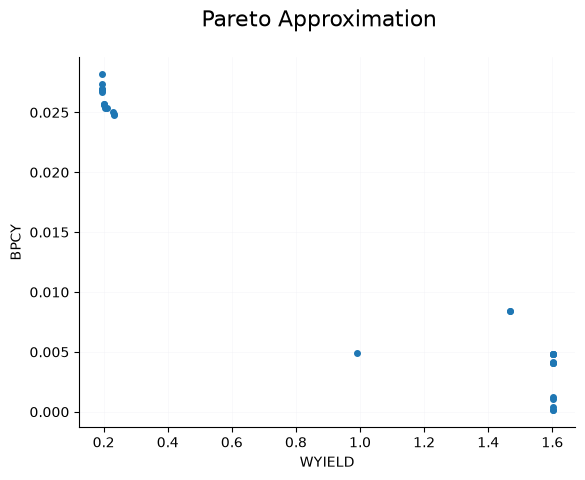

In [5]:
ea.plot()

The solutions and their fitness values:

In [6]:
df = ea.dataframe()
df

,Modification,Size,WYIELD,BPCY
0,{'R_TYRTAim': 32},1,0.194214,0.027393
1,"{'R_FUM': 0.25, 'R_TYRTAim': 32, 'R_PINOS_SC':...",3,0.195259,0.026988
2,"{'R_FUM': 0.25, 'R_TYRTAim': 32, 'R_SERTRS': 0...",6,1.600874,0.004088
3,"{'R_TYRTAim': 32, 'R_IPMD': 16}",2,0.201049,0.025732
4,"{'R_TYRTAim': 32, 'R_FUM': 0.25, 'R_TRPS1': 0....",5,1.600874,0.004198
5,"{'R_MDH': 0.125, 'R_TYRTAim': 32, 'R_PINOS_SC'...",4,0.230899,0.024837
6,"{'R_TYRTAim': 32, 'R_PINOS_SC': 32, 'R_IPMD': ...",4,0.230980,0.024783
7,"{'R_TYRTAim': 32, 'R_IPMD': 16, 'R_PINOS_SC': 2}",3,0.201316,0.025724
8,"{'R_TYRTAim': 32, 'R_PINOS_SC': 32, 'R_IPMD': ...",4,0.209905,0.025382
9,"{'R_FUM': 0.25, 'R_TYRTAim': 32, 'R_TRDR': 0.2...",5,1.468529,0.008419


## Inspecting the solutions

The growth and tyrosine secretion of each non-dominated solution, predicted by lMOMA (the method BPCY uses), sorted by BPCY:

In [7]:
import pandas as pd
from mewpy.optimization.ea import non_dominated_population

front = non_dominated_population(final_pop)
rows = []
for s in front:
    res = problem.simulate(solution=s.values, method='lMOMA')
    rows.append({'modification': s.values,
                 'size': len(s.values),
                 'WYIELD': s.fitness[0],
                 'BPCY': s.fitness[1],
                 'growth': res.fluxes[BIOMASS_ID],
                 'tyrosine': res.fluxes[PRODUCT_ID]})

pd.DataFrame(rows).sort_values('BPCY', ascending=False)

,modification,size,WYIELD,BPCY,growth,tyrosine
11,"{'R_TYRTAim': 32, 'R_FUM': 2, 'R_PINOS_SC': 32}",3,0.194067,0.028193,0.506800,0.556286
0,{'R_TYRTAim': 32},1,0.194214,0.027393,0.506107,0.541254
1,"{'R_FUM': 0.25, 'R_TYRTAim': 32, 'R_PINOS_SC':...",3,0.195259,0.026988,0.499721,0.540055
10,"{'R_TYRTAim': 32, 'R_FUM': 0.25}",2,0.195374,0.026984,0.499660,0.540044
3,"{'R_TYRTAim': 32, 'R_IPMD': 16}",2,0.201049,0.025732,0.458898,0.560102
6,"{'R_TYRTAim': 32, 'R_IPMD': 16, 'R_PINOS_SC': 2}",3,0.201316,0.025724,0.458743,0.560104
13,"{'R_PINOS_SC': 8, 'R_TYRTAim': 32, 'R_IPMD': 16}",3,0.202229,0.025656,0.457328,0.560121
7,"{'R_TYRTAim': 32, 'R_PINOS_SC': 32, 'R_IPMD': ...",4,0.209905,0.025382,0.451680,0.560192
9,"{'R_MDH': 0.125, 'R_TYRTAim': 32, 'R_IPMD': 16...",4,0.228610,0.025025,0.444350,0.560283
4,"{'R_MDH': 0.125, 'R_TYRTAim': 32, 'R_PINOS_SC'...",4,0.230899,0.024837,0.440486,0.560331


The solution with the highest BPCY:

In [8]:
best = max(front, key=lambda s: s.fitness[1])  # fitness: [WYIELD, BPCY]
best.values

{'R_TYRTAim': 32, 'R_FUM': 2, 'R_PINOS_SC': 32}

pFBA assumes that the mutant grows optimally; lMOMA, that its fluxes change as little as possible from the wild type. The two can predict different phenotypes for the same modifications:

In [9]:
pd.DataFrame({method: problem.simulate(solution=best.values, method=method).fluxes
              for method in ['pFBA', 'lMOMA']}).loc[[BIOMASS_ID, PRODUCT_ID, GLC]]

,pFBA,lMOMA
R_biomass_SC5_notrace,0.553735,0.506800
R_EX_tyr_L_e_,0.562821,0.556286
R_EX_glc_e_,-10.000000,-10.000000


With these modifications, both methods predict tyrosine secretion (0.563 with pFBA, 0.556 with lMOMA); lMOMA predicts lower growth (0.507 against 0.554). BPCY uses the lMOMA prediction.

The production envelope of L-tyrosine with the modifications applied. The problem's simulator carries the medium:

<Axes: xlabel='R_biomass_SC5_notrace', ylabel='R_EX_tyr_L_e_'>

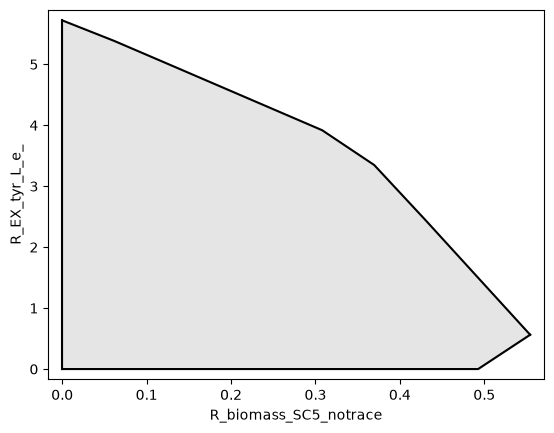

In [10]:
from mewpy.visualization.envelope import plot_flux_envelope

plot_flux_envelope(problem.simulator, BIOMASS_ID, PRODUCT_ID, constraints=best.constraints)